# Analysis of the 2D-grid-approach results

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os
import corner

# Visual settings
%config InlineBackend.figure_format='retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'
    
# Latex font
plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)


%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from matplotlib import colors
#plt.rcParams['figure.figsize'] = [9,7]  # Adjust the size as needed for the plots
from mpl_toolkits.mplot3d import Axes3D

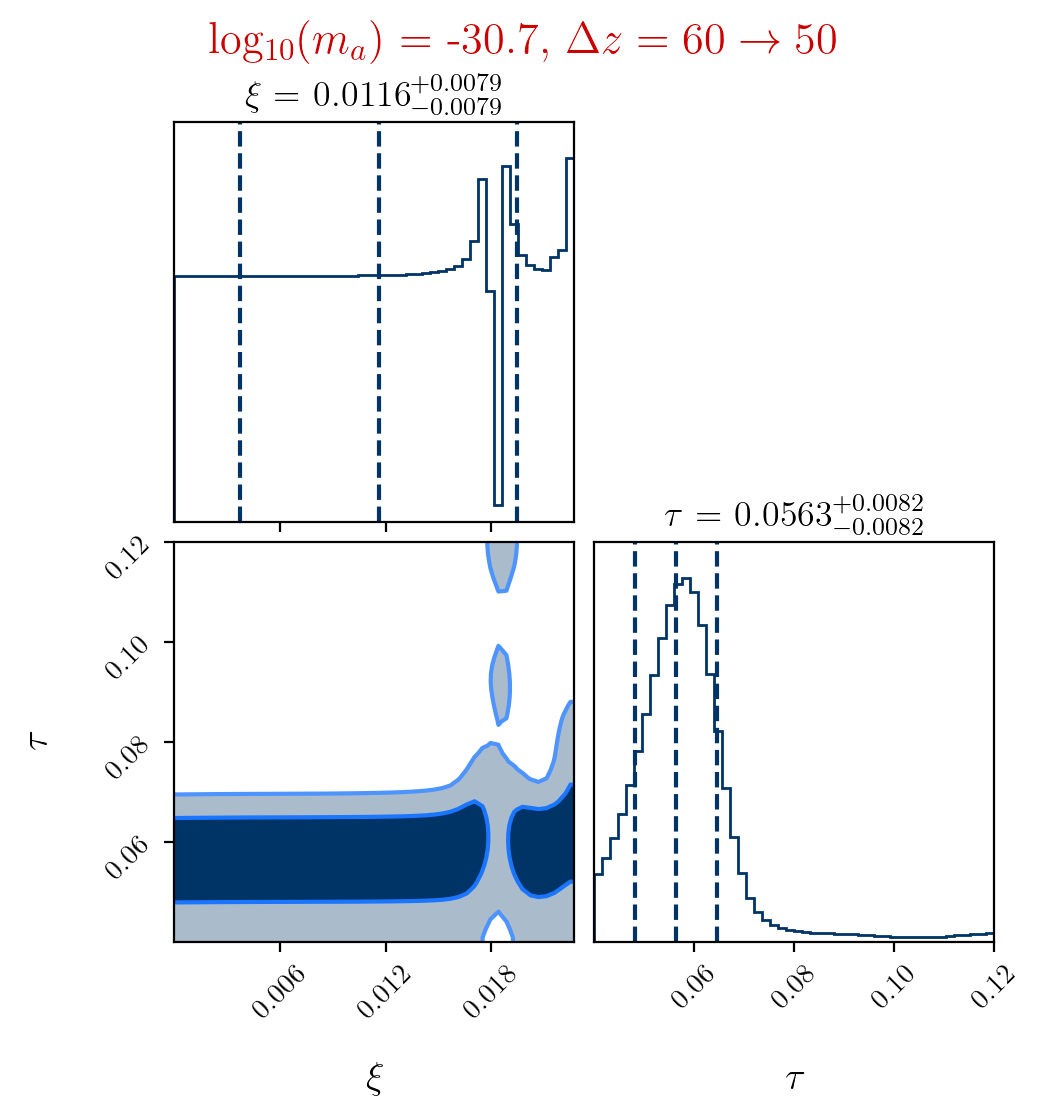

In [2]:
# ==============================================================================
# CORNER-STYLE PLOT FROM THE 2D GRID RESULT (single redshift bin / single mass)
# Same visual style as the MCMC corner plots, but built from the EXACT grid
# likelihood instead of MCMC samples: each grid point is a pseudo-sample
# weighted by its normalized likelihood (weights=P.flatten()).
# ==============================================================================

GRID_FILE = 'EE_grid_search/grid_search_output/Grid2D_EE_logma-30.6_z60-50_50x50.npz'  #EE-only grid
#GRID_FILE = 'joint_grid_search/grid_search_output/Grid2D_joint_logma-30.6_z60-50_50x50.npz'   #Joint EE+EB+BB grid
 
labels = [r'$\xi$', r'$\tau$']

data      = np.load(GRID_FILE)
xi_grid   = data['xi']
tau_grid  = data['tau']
chi2_grid = data['chi2']

min_chi2 = np.min(chi2_grid)
like = np.exp(-0.5 * (chi2_grid - min_chi2))
P = like / like.sum()

# Flatten the grid into "samples" + weights (this is the trick: corner just
# needs points + weights, it doesn't care whether they come from an MCMC
# chain or a deterministic grid).
samples = np.column_stack([xi_grid.flatten(), tau_grid.flatten()])
weights = P.flatten()

levels = [0.6827, 0.9545]   # same choice as in the MCMC corner plots

fig = corner.corner(
    samples,
    weights=weights,
    labels=labels,
    show_titles=True,
    title_kwargs={"fontsize": 13, "fontweight": "bold"},
    title_fmt='.4f',
    quantiles=[0.16, 0.5, 0.84],
    levels=levels,
    plot_density=False,
    plot_datapoints=False,
    fill_contours=True,
    smooth=1.5,
    bins=[xi_grid.shape[0], tau_grid.shape[1]],  # match native grid resolution
    color="#003366",
    contour_kwargs={"colors": ["#4d94ff", "#1a75ff", "#005ce6"]},
    hist_kwargs={"lw": 2, "color": "#003366", "histtype": "step"},
    label_kwargs={"fontsize": 14},
    max_n_ticks=4
)

fig.suptitle(r"log$_{10}(m_a)$ = -30.7, $\Delta z = 60 \rightarrow 50$",
             fontsize=16, color="#cc0000", y=1.02)

#fig.savefig("corner_grid_z60-50.pdf", bbox_inches='tight', dpi=300)
plt.show()

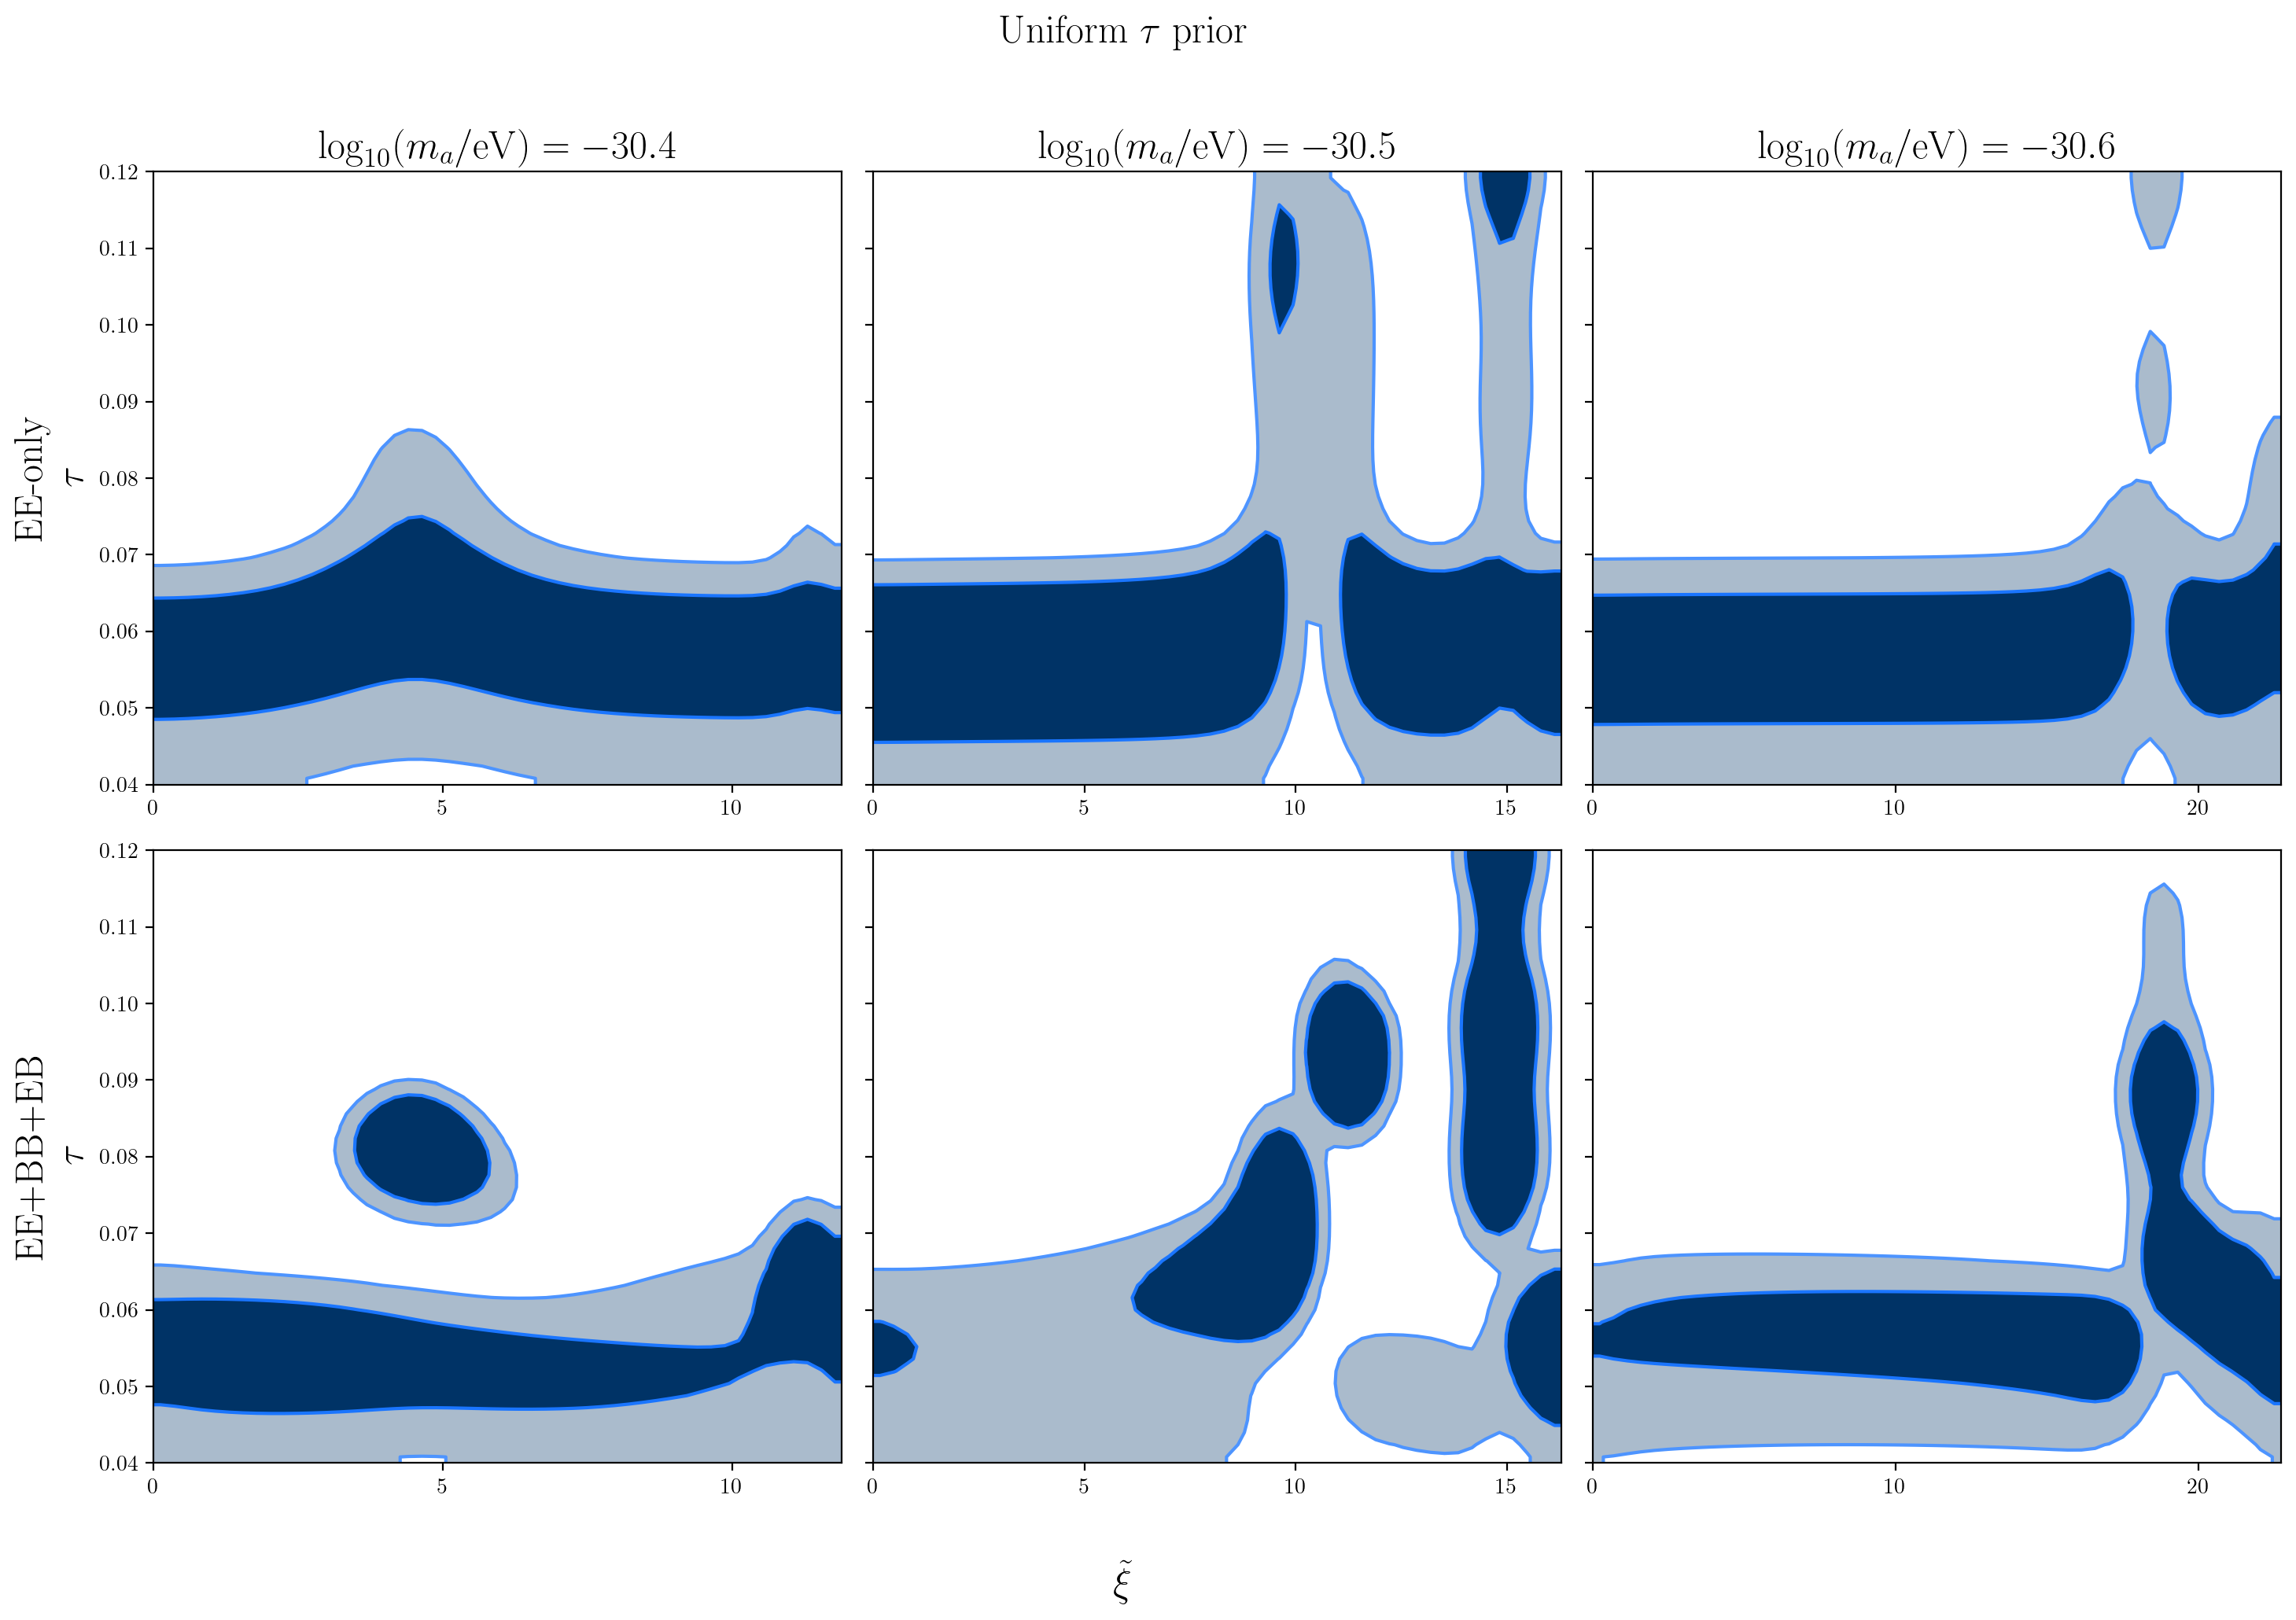

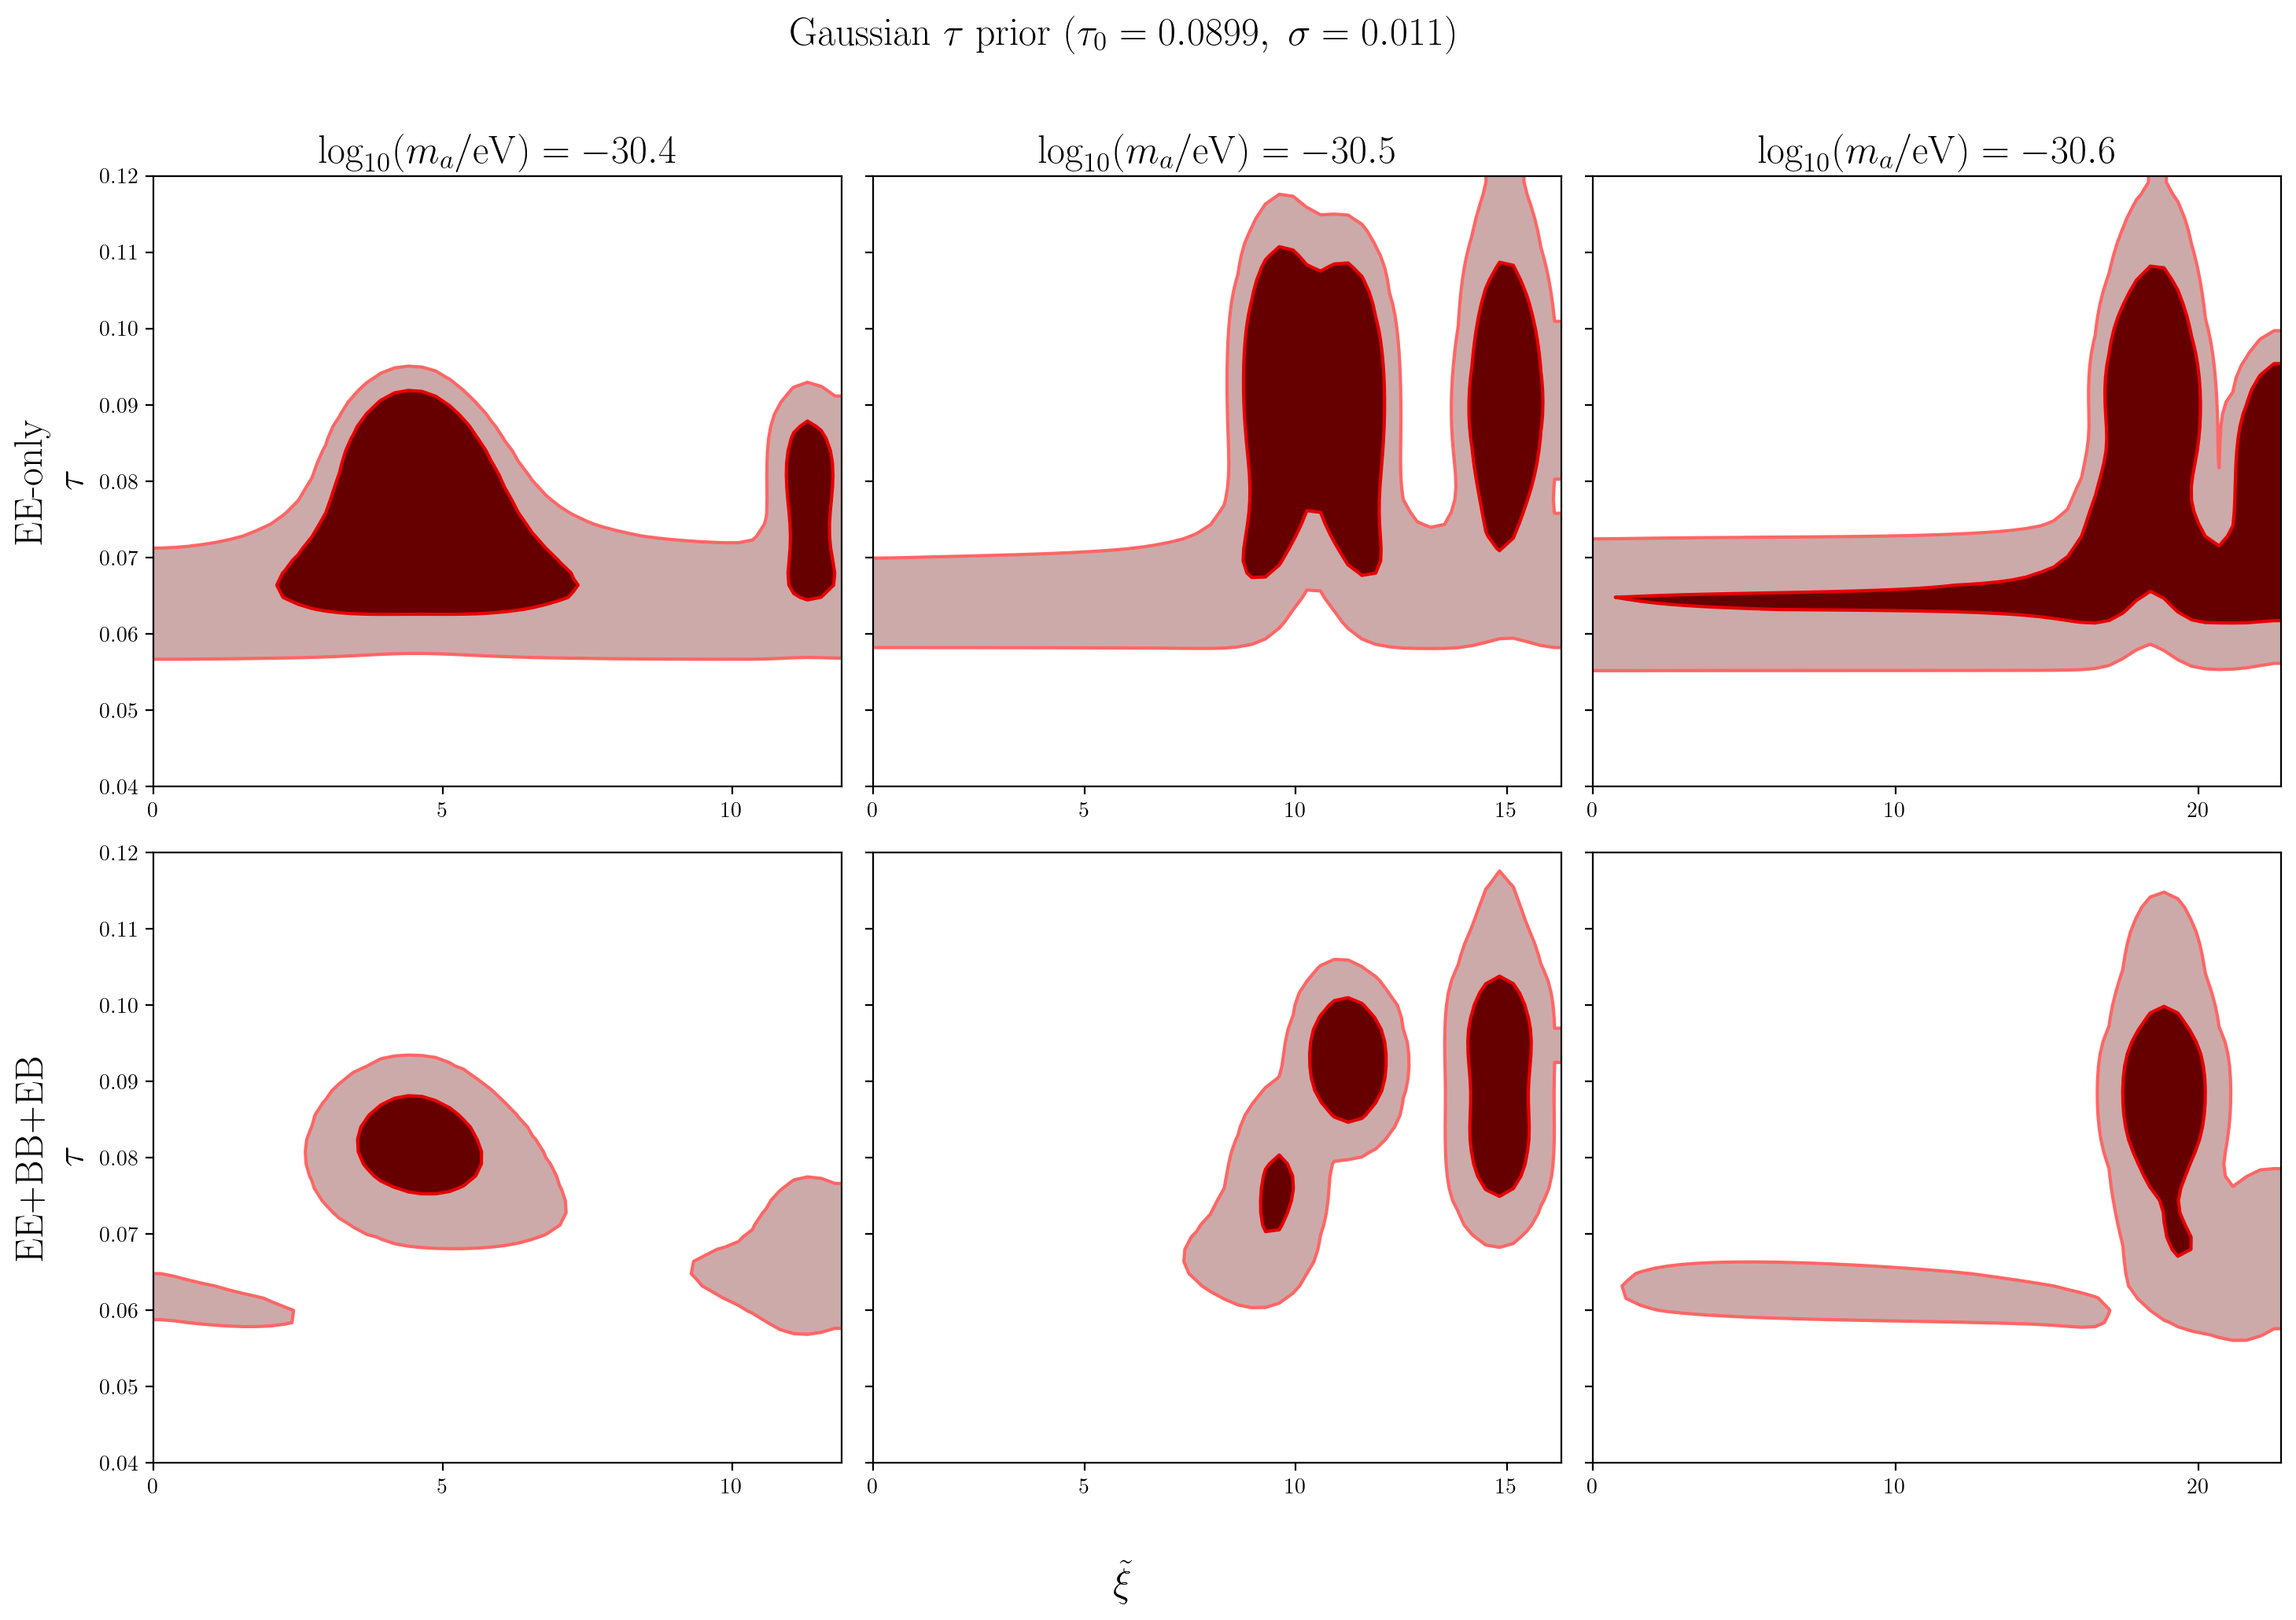

In [3]:
"""
3x2 contour-only plots (xi, tau), EE-only (row 1) vs joint EE+BB+EB (row 2),
columns = 3 masses. Two versions: uniform tau prior, Gaussian tau prior.

Same visual style as your corner.corner plots (color="#003366",
contour shades ["#4d94ff", "#1a75ff", "#005ce6"]), but only the 2D contour
panel (no 1D histograms), via corner.hist2d. x-axis (xi_tilde) NOT shared
across columns, since xi_crit varies significantly with mass; y-axis (tau)
shared across all panels since the prior range is the same for all masses.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from corner import hist2d

rc('text', usetex=True)
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})

# ==============================================================================
# 0. CONFIG
# ==============================================================================
masses = [-30.4, -30.5, -30.6]
levels = [0.6827, 0.9545]
grid_res = 50

mu_tau, sigma_tau = 0.089858, 0.011  # Gaussian tau prior (CMB+BAO)

ee_dir    = 'EE_grid_search/grid_search_output'
joint_dir = 'joint_grid_search/grid_search_output'

palettes = {
    'blue':    dict(color="#003366", contour=["#4d94ff", "#1a75ff", "#005ce6"]),
    'darkred': dict(color="#660000", contour=["#ff6666", "#e60000", "#990000"]),
}


def grid_path(kind, logm):
    if kind == 'EE':
        return f'{ee_dir}/Grid2D_EE_logma{logm}_z60-50_{grid_res}x{grid_res}.npz'
    else:
        # NOTE: verify case (JOINT vs joint) against the actual filenames on disk
        return f'{joint_dir}/Grid2D_joint_logma{logm}_z60-50_{grid_res}x{grid_res}.npz'


# ==============================================================================
# 1. LOAD + WEIGHT
# ==============================================================================
def load_weighted_samples(kind, logm, gaussian_prior=False):
    data = np.load(grid_path(kind, logm))
    xi_grid, tau_grid, chi2_grid = data['xi'], data['tau'], data['chi2']

    min_chi2 = np.min(chi2_grid)
    like = np.exp(-0.5 * (chi2_grid - min_chi2))

    if gaussian_prior:
        prior = np.exp(-0.5 * ((tau_grid - mu_tau) / sigma_tau) ** 2)
        like = like * prior

    P = like / like.sum()

    xi_tilde_flat = xi_grid.flatten() * 1e3   # xi_tilde = xi * 1e3
    tau_flat = tau_grid.flatten()
    weights = P.flatten()

    return xi_tilde_flat, tau_flat, weights


# ==============================================================================
# 2. BUILD THE 3x2 CONTOUR-ONLY FIGURE
# ==============================================================================
def make_contour_grid(gaussian_prior, out_file):
    palette = 'darkred' if gaussian_prior else 'blue'
    pal = palettes[palette]

    fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10),
                             sharex=False, sharey=True)

    row_kinds  = ['EE', 'joint']
    row_labels = ['EE-only', 'EE+BB+EB']

    for row, kind in enumerate(row_kinds):
        for col, logm in enumerate(masses):
            ax = axes[row, col]
            xi_t, tau, w = load_weighted_samples(kind, logm, gaussian_prior)

            hist2d(
                xi_t, tau, weights=w, ax=ax,
                levels=levels,
                plot_density=False, plot_datapoints=False,
                fill_contours=True, smooth=1.5,
                bins=grid_res,
                color=pal['color'],
                contour_kwargs={"colors": pal['contour']},
            )

            if row == 0:
                ax.set_title(rf"$\log_{{10}}(m_a/\mathrm{{eV}}) = {logm:.1f}$", fontsize=18)
            if col == 0:
                ax.set_ylabel(row_labels[row] + "\n" + r"$\tau$", fontsize=18)
            ax.tick_params(axis='both', labelsize=10)
            ax.locator_params(axis='x', nbins=4)

    fig.supxlabel(r'$\tilde\xi$', fontsize=18)

    if gaussian_prior:
        title = rf'Gaussian $\tau$ prior ($\tau_0={mu_tau:.4f},\ \sigma={sigma_tau}$)'
        fig.suptitle(title, fontsize=18, y=1.02, color='k')
    else:
        fig.suptitle(r'Uniform $\tau$ prior', fontsize=18, y=1.02)

    plt.tight_layout(rect=[0.02, 0.02, 1, 1])
    fig.savefig(out_file, bbox_inches='tight', dpi=300)
    plt.show()


# ==============================================================================
# 3. RUN
# ==============================================================================
make_contour_grid(gaussian_prior=False, out_file='contours_uniform_prior_3x2.pdf')
make_contour_grid(gaussian_prior=True,  out_file='contours_gaussian_prior_3x2.pdf')